# 1. Real burst and inverse question
Recover residual cold-plasma dispersion and the intrinsic Gaussian pulse morphology of FRB 20220502B. The bound observations retain all 16,384 native channels and 162 time bins; 10,712 channels have nonzero quality weights. A mean over 64 channels is used only to display waterfalls. The selected published branch fixes scattering to zero as a conditional model assumption, not as a measurement of absent scattering.

| Parameter | Unit | Interpretation |
|---|---|---|
| alpha | 1 | Logarithm base 10 of the intrinsic peak intensity relative to 1 U. |
| t0 | s | Intrinsic pulse center at 400.1953125 MHz, in the relative clock. |
| sigma | s | Gaussian standard deviation, rather than FWHM. |
| deltaDM | pc/cm3 | Offset from the already applied dispersion measure of 623.6785965856119. |
| gamma, beta | 1 | Spectral index and running at the fixed reference frequency. |

No Jansky calibration is available. The intrinsic reference fluence is 10^alpha * sigma * sqrt(2 pi), in U s. The source reader converts the first frequency edge, 400.2197265625 MHz, to the first channel center, 400.23193359375 MHz. All native center labels are retained. Channel width is 0.0244140625 MHz; exposure width is 0.0009830400813370943 s. The source clock origin, 1060314.72377856, is fixed. The relative array starts at zero; this clock origin is not an additional unknown.

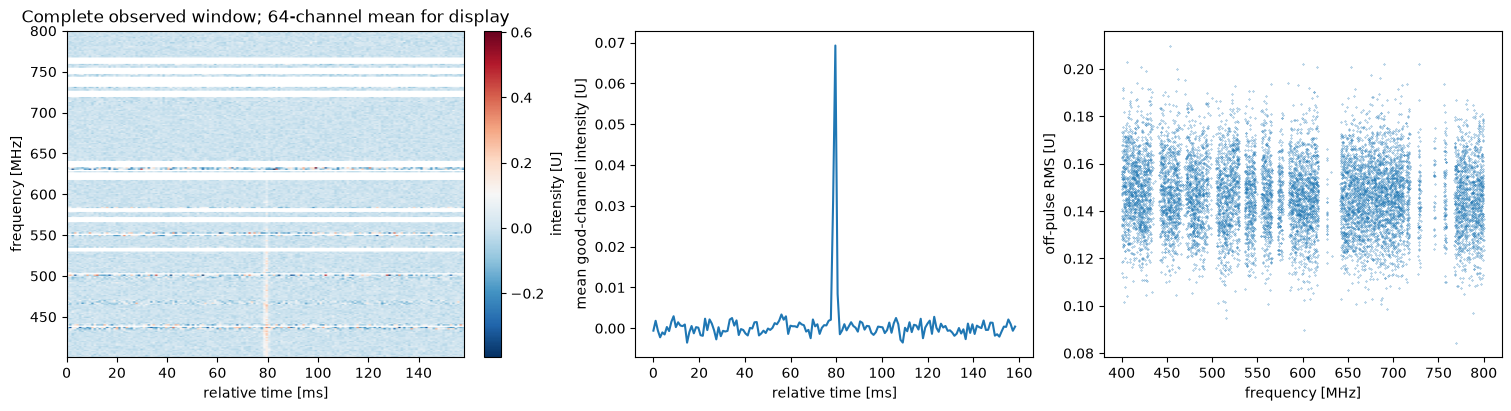

Native data (16384, 162) used channels 10712 native dtype float64


In [1]:
import os,sys,time,json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown,display
ROOT=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
from src.preprocessing import load
from src.physics_model import gaussian_model,NOMINAL_DM,REF_FREQ
from src.solvers import reconstruct,fit_fixed
from src.visualization import display_waterfall,model_comparison
d=load();good=d['good_channels'];y=d['measurements'];noise=d['noise_rms'][good,None];ts=d['times'];freq=d['frequencies'];dt=ts[1]-ts[0]
fig,axs=plt.subplots(1,3,figsize=(15,4),layout='constrained')
im=axs[0].imshow(display_waterfall(y,good),origin='lower',aspect='auto',extent=[ts[0]*1000,ts[-1]*1000,freq[0],freq[-1]],cmap='RdBu_r');fig.colorbar(im,ax=axs[0],label='intensity [U]');axs[0].set_xlabel('relative time [ms]');axs[0].set_ylabel('frequency [MHz]');axs[0].set_title('Complete observed window; 64-channel mean for display')
axs[1].plot(ts*1000,y[good].mean(0));axs[1].set_xlabel('relative time [ms]');axs[1].set_ylabel('mean good-channel intensity [U]')
axs[2].plot(freq[good],d['noise_rms'][good],'.',ms=.5);axs[2].set_xlabel('frequency [MHz]');axs[2].set_ylabel('off-pulse RMS [U]');plt.show()
print('Native data',y.shape,'used channels',good.sum(),'native dtype',y.dtype)

# 2. Dispersion, spectral law and exposure physics
Let nu be a frequency inside channel k, nu(k) its center, t(n) an exposure center, and nu(r) the fixed reference frequency. D0 is the dispersion measure already removed by incoherent dedispersion; deltaD is the inferred residual. With K = 4149.377593360996 MHz² s cm³/pc,

$$T_k(\nu)=t_0+K(D_0+\delta D)(\nu^{-2}-\nu_r^{-2})-KD_0(\nu_k^{-2}-\nu_r^{-2}),$$
$$G_k(\nu,t)=10^\alpha\exp[\gamma\ln(\nu/\nu_r)+\beta\ln^2(\nu/\nu_r)]\exp[-(t-T_k(\nu))^2/(2\sigma^2)].$$

The model averages 8 frequency midpoints and 4 time midpoints per native bin. Incoherent dedispersion aligns channel centers only; smearing within each channel still depends on the full D0 + deltaD. The visible quality mask combines acquisition RFI exclusions with finite, nonzero noise RMS. It does not depend on fitted residuals. Each channel's weight is 1/RMS, estimated from the first 50 visible bins without mean subtraction. The Judge reports the mean of squared, noise-normalized residuals over all 10,712 x 162 used samples, without subtracting fitted degrees of freedom. Every inferred parameter enters the forward prediction.

An independent analytic Gaussian exposure integral, evaluated using erf differences and 16, 32 or 64 frequency subchannels, checks integration convergence. Its difference from the original 8 x 4 response has RMS 0.000506 times the noise RMS and a maximum of about 0.0124 noise units in one bin. This validates the selected Gaussian response at its fitted width; it does not validate the underresolved scattering fit.

In [2]:
with np.load('test/fixtures/upstream_gaussian.npz') as f:
 q_fixture=f['input_parameters'].copy();ucheck=gaussian_model(q_fixture,freq,ts);parity=np.max(abs(ucheck[f['input_channels']]-f['output_model']));print('Original same-parameter forward maximum error:',parity);assert parity<2e-12
checks=[]
for nf in [16,32,64]:
 fine=gaussian_model(q_fixture,freq,ts,ff=nf,analytic_time=True);difference=(fine[good]-ucheck[good])/noise;checks.append([nf,float(np.sqrt(np.mean(difference**2))),float(np.max(abs(difference)))])
rows=['| Analytic time / frequency count | Model difference RMS / noise [1] | Maximum absolute difference / noise [1] |','|---|---:|---:|']
for row in checks:rows.append('| '+' | '.join(f'{v:.12g}' for v in row)+' |')
display(Markdown('\n'.join(rows)))

Original same-parameter forward maximum error: 0.0


| Analytic time / frequency count | Model difference RMS / noise [1] | Maximum absolute difference / noise [1] |
|---|---:|---:|
| 16 | 0.000473358972458 | 0.0116706542765 |
| 32 | 0.000499128393671 | 0.0122650811845 |
| 64 | 0.000505600200702 | 0.0124135584061 |

# 3. Complete active six-parameter reconstruction
The following cell actively fits all native observations using local Gaussian, plasma-dispersion and running-power-law operators. Initialization comes from the observed temporal peak and public data alone. General SciPy least squares with a finite-difference Jacobian matches the selected original fit path. No archived fitted parameters or cached burst answer initialize this reconstruction. A complete run takes about three minutes on one CPU thread.

Actual complete seconds 160.38848409999628 optimizer {'optimizer_success': True, 'cost': 896046.4560108084, 'nfev': 10, 'message': '`ftol` termination condition is satisfied.'}


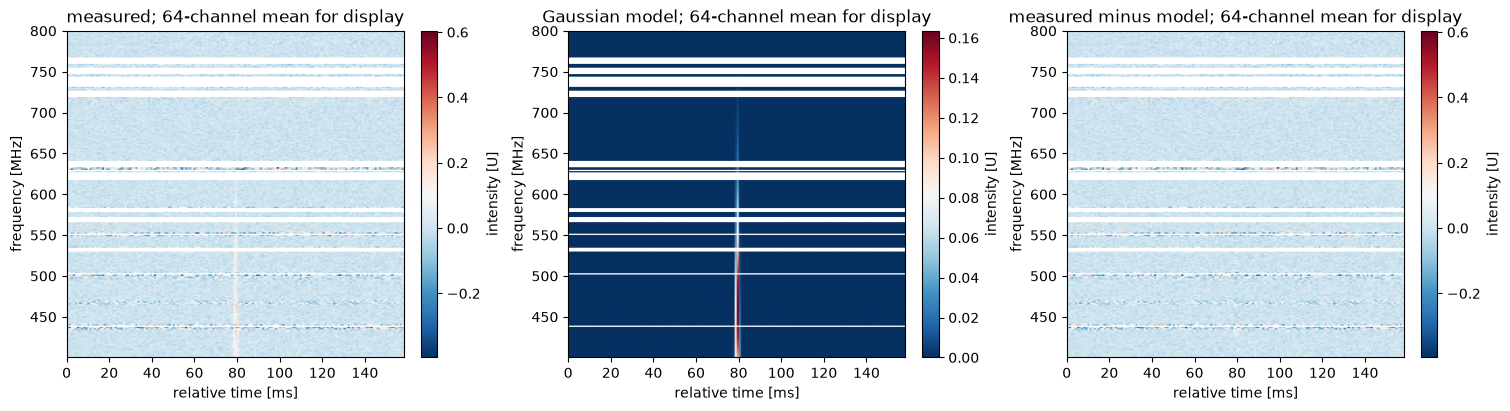

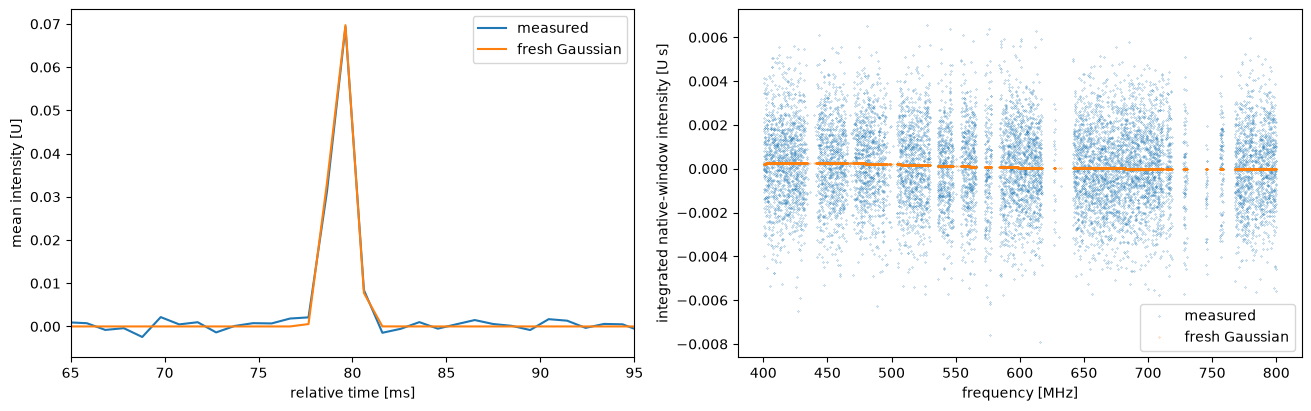

In [3]:
t=time.perf_counter();fresh,info=reconstruct(d);elapsed=time.perf_counter()-t;q=fresh['reconstruction'][0];model=gaussian_model(q,freq,ts);np.savez('output/reconstruction.npz',**fresh)
print('Actual complete seconds',elapsed,'optimizer',info)
model_comparison(d,model);plt.show()
fig,axs=plt.subplots(1,2,figsize=(13,4),layout='constrained')
for values,label in [(y,'measured'),(model,'fresh Gaussian')]:
 profile=values[good].mean(0);axs[0].plot(ts*1000,profile,label=label);spectrum=np.sum(values,axis=1)*dt;axs[1].plot(freq[good],spectrum[good],'.',ms=.4,label=label)
axs[0].set_xlim(65,95);axs[0].set_xlabel('relative time [ms]');axs[0].set_ylabel('mean intensity [U]');axs[0].legend();axs[1].set_xlabel('frequency [MHz]');axs[1].set_ylabel('integrated native-window intensity [U s]');axs[1].legend();plt.show()

# 4. Independent source result and alternative-model diagnosis
The archived Gaussian result is the original six-parameter fit actually executed on these exact native observations. It is a method reference, not independent physical truth. The seven-parameter source extension also ran, but converged to a worse weighted cost with sigma about 6.63e-7 s, far below one quarter of an exposure. Optimizer termination does not establish physical validity: this result remains an explicitly labeled, underresolved local minimum rather than the selected scattering reconstruction.

The independent integration check supports the Gaussian branch at its fitted width. An old fitted dispersion measure is never used as applied acquisition calibration. The tables distinguish the known applied value D0, inferred residual deltaDM, and absolute model dispersion D0 + deltaDM. The source and fresh Gaussian predictions nearly coincide; the scattering curve is retained as a failed-resolution diagnostic.

| Parameter | Unit | Actual source Gaussian | Fresh local Gaussian |
|---|---|---:|---:|
| alpha | 1 | -0.545034474346 | -0.545034474346 |
| t0 | s | 0.079368823113 | 0.079368823113 |
| sigma | s | 0.000331760200515 | 0.000331760200515 |
| deltaDM | pc/cm3 | -0.00307494161027 | -0.00307494161027 |
| gamma | 1 | 2.98716634727 | 2.98716634727 |
| beta | 1 | -16.1342520392 | -16.1342517987 |
| Absolute DM (D0 + deltaDM) | pc/cm3 | 623.675521644 | 623.675521644 |
| Intrinsic reference fluence | U s | 0.000237071716765 | 0.000237071716765 |

| Actually executed model | Weighted mean square [1] | Intrinsic sigma (s) |
|---|---:|---:|
| Source Gaussian | 1.03270182282 | 0.000331760200515 |
| FreshGaussian | 1.03270182282 | 0.000331760200515 |
| Source: seven-parameter underresolved minimum | 1.03275662352 | 6.63065267337e-07 |

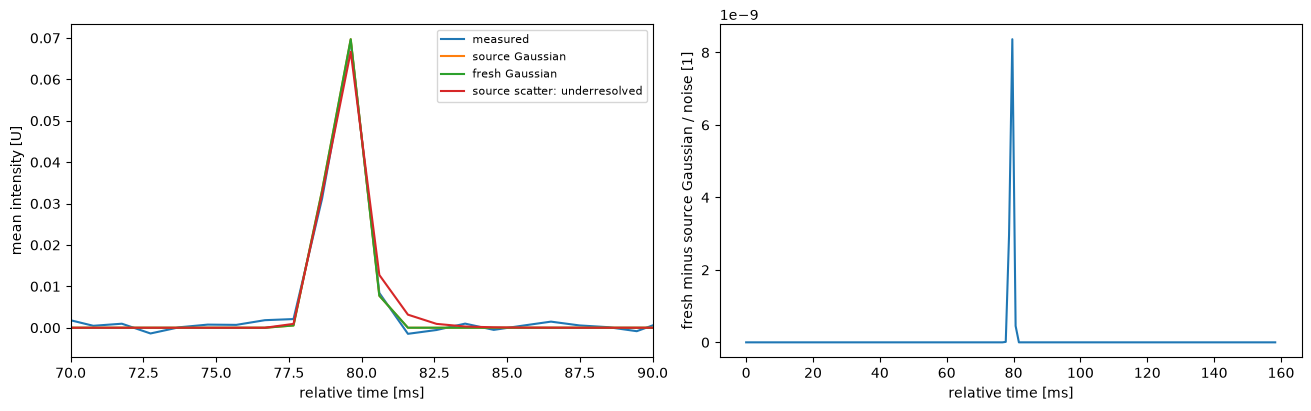

In [4]:
with np.load('notebooks/reference_outputs/upstream_fit.npz') as f:uq=f['reconstruction'][0];um=f['modeled_spectra'][0]
with np.load('notebooks/reference_outputs/scattering_alias_diagnostic.npz') as f:sq=f['parameters'];sm=f['modeled_spectra'][0]
def quality(m,data=d):return float(np.mean(((data['measurements'][good]-m[good])/data['noise_rms'][good,None])**2))
names=['alpha','t0','sigma','deltaDM','gamma','beta'];units=['1','s','s','pc/cm3','1','1'];rows=['| Parameter | Unit | Actual source Gaussian | Fresh local Gaussian |','|---|---|---:|---:|']
for name,unit,u,v in zip(names,units,uq,q):rows.append(f'| {name} | {unit} | {u:.12g} | {v:.12g} |')
rows.append(f'| Absolute DM (D0 + deltaDM) | pc/cm3 | {NOMINAL_DM+uq[3]:.12g} | {NOMINAL_DM+q[3]:.12g} |');rows.append(f'| Intrinsic reference fluence | U s | {10**uq[0]*uq[2]*np.sqrt(2*np.pi):.12g} | {10**q[0]*q[2]*np.sqrt(2*np.pi):.12g} |');display(Markdown('\n'.join(rows)))
rows=['| Actually executed model | Weighted mean square [1] | Intrinsic sigma (s) |','|---|---:|---:|',f'| Source Gaussian | {quality(um):.12g} | {uq[2]:.12g} |',f'| FreshGaussian | {quality(model):.12g} | {q[2]:.12g} |',f'| Source: seven-parameter underresolved minimum | {quality(sm):.12g} | {sq[2]:.12g} |'];display(Markdown('\n'.join(rows)))
fig,axs=plt.subplots(1,2,figsize=(13,4),layout='constrained')
for a,label in [(y,'measured'),(um,'source Gaussian'),(model,'fresh Gaussian'),(sm,'source scatter: underresolved')]:axs[0].plot(ts*1000,a[good].mean(0),label=label)
axs[0].set_xlim(70,90);axs[0].set_xlabel('relative time [ms]');axs[0].set_ylabel('mean intensity [U]');axs[0].legend(fontsize=8)
axs[1].plot(ts*1000,np.sqrt(np.mean(((model[good]-um[good])/noise)**2,axis=0)));axs[1].set_xlabel('relative time [ms]');axs[1].set_ylabel('fresh minus source Gaussian / noise [1]');plt.show()

# 5. Actual physical ablations and robustness
These alternatives are fresh local refits initialized from the current, raw-derived standard estimate. They do not start from archived parameters. Fixing deltaDM to zero tests residual dispersion. Fixing beta to zero tests a power law without spectral running. Omitting sub-bin averaging tests the effect of finite channel widths and exposures. The table reports both the approximation's own response score and its score under the standard 8 x 4 response.

A matched noiseless warm-start control and a fit after adding noise at 5% of the off-pulse RMS use the same current initialization and stopping rules. Compare the perturbed result with that matched control. Added noise never replaces the bound benchmark observations or the saved standard output. These are local sensitivity diagnostics, not proofs of global model selection or calibrated parameter uncertainty.

deltaDM fixed at zero {'optimizer_success': True, 'cost': 896046.8536000587, 'nfev': 4, 'message': '`ftol` termination condition is satisfied.'}


spectral running fixed at zero {'optimizer_success': True, 'cost': 896159.529757925, 'nfev': 21, 'message': '`ftol` termination condition is satisfied.'}


no channel/exposure integration {'optimizer_success': True, 'cost': 896072.8822141325, 'nfev': 9, 'message': '`ftol` termination condition is satisfied.'}


Actual five diagnostic inverse calls: seconds 407.82295549998526


| Actual fit | Own response score on bound data (1) | Standard 8 x 4 score [1] | sigma [ms] | deltaDM [pc/cm3] |
|---|---:|---:|---:|---:|
| standard | 1.03270182282 | 1.03270182282 | 0.331760200515 | -0.00307494161027 |
| deltaDM fixed at zero | 1.03270228105 | 1.03270228105 | 0.322865605882 | 0 |
| spectral running fixed at zero | 1.03283214136 | 1.03283214136 | 0.0617719728923 | 0.0161962026504 |
| no channel/exposure integration | 1.03273227926 | 1.03284378315 | 0.573661278093 | -0.0156215544613 |
| matched warm-start control | 1.03270182281 | 1.03270182281 | 0.331708944777 | -0.0030603778353 |
| added 5% RMS noise | 1.03270183255 | 1.03270183255 | 0.333474093013 | -0.00329132582505 |

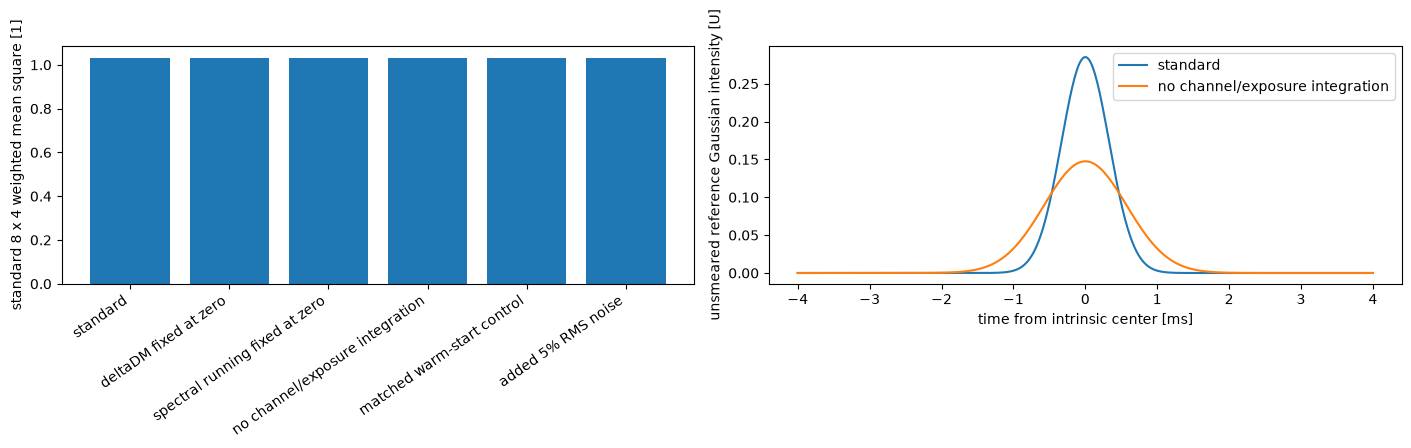

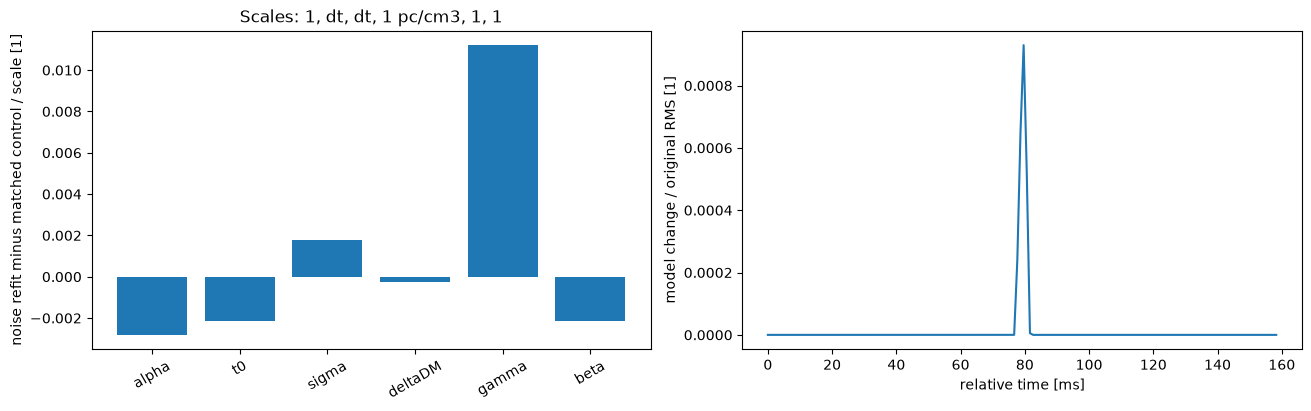

In [5]:
t=time.perf_counter();variants={'standard':(q,model,8,4)}
for name,fixed,ff,ft in [('deltaDM fixed at zero',{'residual_dm':0.},8,4),('spectral running fixed at zero',{'spectral_running':0.},8,4),('no channel/exposure integration',{},1,1)]:
 result,diagnostic=fit_fixed(d,fixed,ff=ff,ft=ft,initial=q);v=result['reconstruction'][0];variants[name]=(v,gaussian_model(v,freq,ts,ff=ff,ft=ft),ff,ft);print(name,diagnostic)
control,ci=fit_fixed(d,initial=q);pert={k:v.copy() for k,v in d.items()};pert['measurements']+=np.random.default_rng(512).normal(size=y.shape)*(.05*d['noise_rms'][:,None]);perturbed,pi=fit_fixed(pert,initial=q)
variants['matched warm-start control']=(control['reconstruction'][0],gaussian_model(control['reconstruction'][0],freq,ts),8,4);variants['added 5% RMS noise']=(perturbed['reconstruction'][0],gaussian_model(perturbed['reconstruction'][0],freq,ts),8,4)
print('Actual five diagnostic inverse calls: seconds',time.perf_counter()-t)
rows=['| Actual fit | Own response score on bound data (1) | Standard 8 x 4 score [1] | sigma [ms] | deltaDM [pc/cm3] |','|---|---:|---:|---:|---:|'];scores=[]
for name,(v,m,ff,ft) in variants.items():
 canonical=quality(gaussian_model(v,freq,ts));scores.append(canonical);rows.append(f'| {name} | {quality(m):.12g} | {canonical:.12g} | {1000*v[2]:.12g} | {v[3]:.12g} |')
display(Markdown('\n'.join(rows)))
fig,axs=plt.subplots(1,2,figsize=(14,4),layout='constrained');axs[0].bar(range(len(scores)),scores);axs[0].set_xticks(range(len(scores)),list(variants),rotation=35,ha='right');axs[0].set_ylabel('standard 8 x 4 weighted mean square [1]')
for name in ['standard','no channel/exposure integration']:
 v=variants[name][0];fine_t=np.linspace(-.004,.004,500);axs[1].plot(fine_t*1000,10**v[0]*np.exp(-.5*(fine_t/v[2])**2),label=name)
axs[1].set_xlabel('time from intrinsic center [ms]');axs[1].set_ylabel('unsmeared reference Gaussian intensity [U]');axs[1].legend();plt.show()
fig,axs=plt.subplots(1,2,figsize=(13,4),layout='constrained');a=control['reconstruction'][0];b=perturbed['reconstruction'][0];scale=np.array([1.,dt,dt,1.,1.,1.]);axs[0].bar(range(6),(b-a)/scale);axs[0].set_xticks(range(6),names,rotation=30);axs[0].set_ylabel('noise refit minus matched control / scale [1]');axs[0].set_title('Scales: 1, dt, dt, 1 pc/cm3, 1, 1')
noise_delta=(variants['added 5% RMS noise'][1][good]-variants['matched warm-start control'][1][good])/noise;axs[1].plot(ts*1000,np.sqrt(np.mean(noise_delta**2,axis=0)));axs[1].set_xlabel('relative time [ms]');axs[1].set_ylabel('model change / original RMS [1]');plt.show()

# 6. Standalone evaluation and interpretation
The Judge computes the full native forward prediction from all six submitted parameters and evaluates every good channel and time bin. It accepts equally good or better measurement fits without enforcing parameter identity. Intrinsic width and fluence are conditional Gaussian quantities; they are not independently measured emission properties. Fixing scattering to zero does not establish that scattering is absent.

The analytic exposure control validates the selected response at this fit, while the underresolved seven-parameter result illustrates why optimizer termination alone is insufficient. Noise RMS is estimated from visible off-pulse samples and may not capture all RFI or statistical dependence. Standard reconstruction uses no amplitude or phase alignment, post-fit rescaling, or hidden fitted-parameter cache.

In [6]:
import subprocess
p=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True,encoding='utf8');print(Path('output/judge_report.json').read_text(encoding='utf8'));assert p.returncode==0

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "weighted_mean_squared_residual": 1.0327018228210718
  },
  "thresholds": {
    "weighted_mean_squared_residual": {
      "comparison": "<=",
      "boundary": 1.0327028555228954
    }
  },
  "errors": []
}
